--- Завантаження, перемішування та нормалізація виконані ---
Загальна кількість записів: 150
Кількість ознак: 4


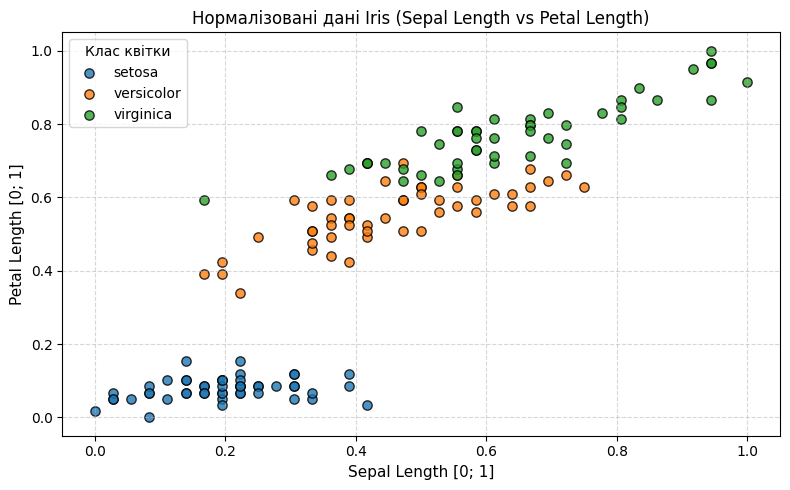

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

df_iris = pd.DataFrame(X, columns=feature_names)
df_iris['label'] = y
df_iris['species'] = [target_names[i] for i in y]

df_shuffled = df_iris.sample(frac=1, random_state=42).reset_index(drop=True)
X_shuffled = df_shuffled[feature_names].values
y_shuffled = df_shuffled['label'].values

scaler = MinMaxScaler()
X_norm = scaler.fit_transform(X_shuffled)

print("--- Завантаження, перемішування та нормалізація виконані ---")
print(f"Загальна кількість записів: {X_norm.shape[0]}")
print(f"Кількість ознак: {X_norm.shape[1]}")

plt.figure(figsize=(8, 5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for class_idx, class_name in enumerate(target_names):
  mask = y_shuffled == class_idx
  plt.scatter(
      X_norm[mask, 0],
      X_norm[mask, 2],
      color=colors[class_idx],
      label=class_name,
      alpha=0.8,
      s=45,
      edgecolors='k',
  )

plt.title('Нормалізовані дані Iris (Sepal Length vs Petal Length)', fontsize=12)
plt.xlabel('Sepal Length [0; 1]', fontsize=11)
plt.ylabel('Petal Length [0; 1]', fontsize=11)
plt.legend(title='Клас квітки')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Розмір навчальної вибірки (train): 112 записів (75%)
Розмір тестової вибірки (test):    38 записів (25%)


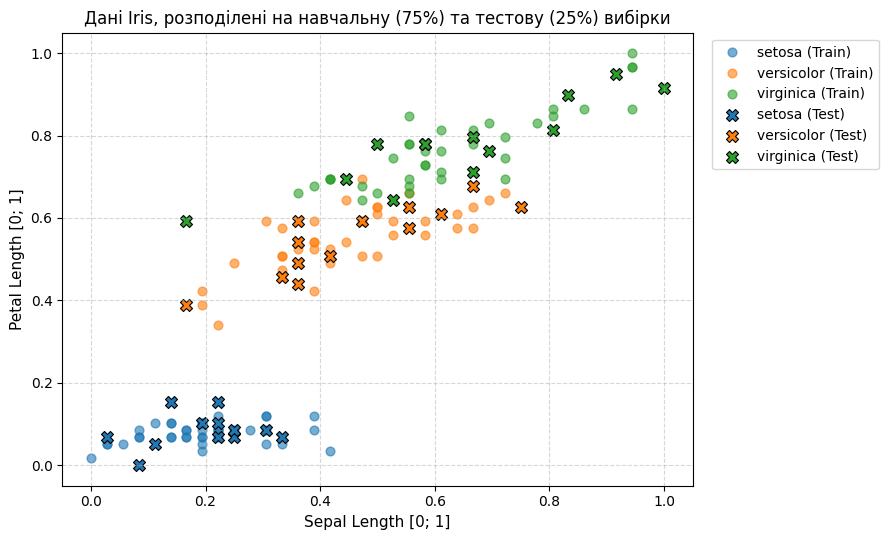

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_norm, y_shuffled, test_size=0.25, random_state=42, stratify=y_shuffled
)

print(f"Розмір навчальної вибірки (train): {X_train.shape[0]} записів (75%)")
print(f"Розмір тестової вибірки (test):    {X_test.shape[0]} записів (25%)")

plt.figure(figsize=(9, 5.5))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for class_idx, class_name in enumerate(target_names):
  mask_train = y_train == class_idx
  plt.scatter(
      X_train[mask_train, 0],
      X_train[mask_train, 2],
      color=colors[class_idx],
      label=f"{class_name} (Train)",
      alpha=0.6,
      s=40,
  )

for class_idx, class_name in enumerate(target_names):
  mask_test = y_test == class_idx
  plt.scatter(
      X_test[mask_test, 0],
      X_test[mask_test, 2],
      color=colors[class_idx],
      marker='X',
      label=f"{class_name} (Test)",
      s=75,
      edgecolors='black',
      linewidth=0.8,
  )

plt.title(
    'Дані Iris, розподілені на навчальну (75%) та тестову (25%) вибірки',
    fontsize=12,
)
plt.xlabel('Sepal Length [0; 1]', fontsize=11)
plt.ylabel('Petal Length [0; 1]', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Оптимальна кількість сусідів: K = 3
Найвища точність (Accuracy) на тесті: 94.74%


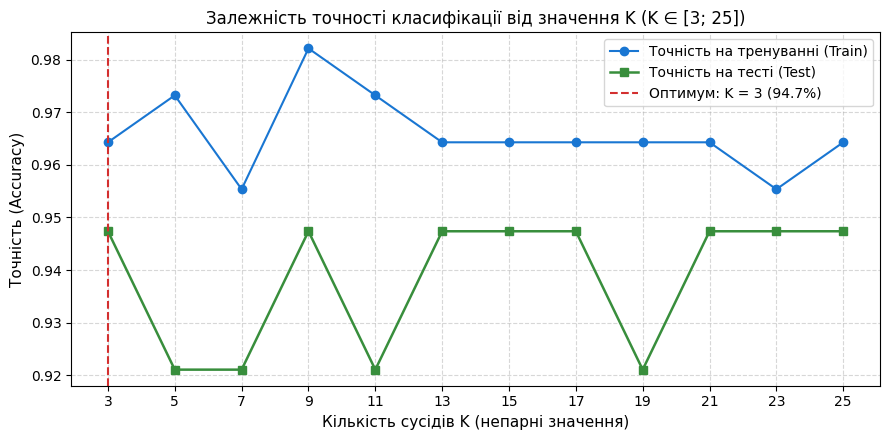

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

k_range = list(range(3, 26, 2))
train_scores = []
test_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train, y_train)

    train_scores.append(accuracy_score(y_train, knn.predict(X_train)))
    test_scores.append(accuracy_score(y_test, knn.predict(X_test)))

best_idx = np.argmax(test_scores)
best_k = k_range[best_idx]
best_test_score = test_scores[best_idx]

print(f"Оптимальна кількість сусідів: K = {best_k}")
print(f"Найвища точність (Accuracy) на тесті: {best_test_score * 100:.2f}%")

plt.figure(figsize=(9, 4.5))
plt.plot(k_range, train_scores, marker='o', label="Точність на тренуванні (Train)", color='#1976d2', linewidth=1.5)
plt.plot(k_range, test_scores, marker='s', label="Точність на тесті (Test)", color='#388e3c', linewidth=1.8)
plt.axvline(x=best_k, color='#d32f2f', linestyle='--', label=f"Оптимум: K = {best_k} ({best_test_score*100:.1f}%)")

plt.title("Залежність точності класифікації від значення K (K ∈ [3; 25])", fontsize=12)
plt.xlabel("Кількість сусідів K (непарні значення)", fontsize=11)
plt.ylabel("Точність (Accuracy)", fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()